# Modularity on the Karate Club Graph
**DSC212: Graph Theory Module, Research Assignment**

Name: Snigdha Rajan |  Roll number: IMS25200

This notebook implements the **spectral modularity method** of Newman (2006) from scratch and applies it **recursively** to Zachary's Karate Club network (34 nodes, 78 edges). After every split it draws the graph, computes four node metrics with NetworkX, and tracks how those metrics evolve.

**Contents:** 1. Setup and data, 2. Modularity matrix, 3. Recursive spectral bisection, 4. Visualisation of each split, 5. Node metrics after each split, 6. Metric evolution, 7. Verification, 8. Discussion, References.

## 1. Setup and data

In [1]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt

EIG_TOL = 1e-10   # leading eigenvalues <= this are treated as "not positive"

In [2]:
G = nx.karate_club_graph()
nodes = sorted(G.nodes())
n, m = G.number_of_nodes(), G.number_of_edges()

# Unweighted adjacency matrix (weight=None ignores any edge weights stored by NetworkX)
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)
k = A.sum(axis=1)                       # degree vector

assert set(np.unique(A)) == {0.0, 1.0} and np.allclose(A, A.T)
assert np.isclose(k.sum(), 2 * m)       # sum of degrees = 2m
print(f"n = {n} nodes, m = {m} edges, sum of degrees = {int(k.sum())} (= 2m)")

n = 34 nodes, m = 78 edges, sum of degrees = 156 (= 2m)


## 2. The modularity matrix
$B = A - \dfrac{k k^\top}{2m}$, where $k k^\top/2m$ is the expected number of edges between each pair of nodes under the degree-preserving null model. The modularity of a two-way split $s\in\{-1,+1\}^n$ is $Q=\frac{1}{4m}s^\top B s$.

In [3]:
B = A - np.outer(k, k) / (2 * m)

# Proposition 1 (symmetric) and Proposition 2 (B @ 1 = 0, so every row sums to zero)
assert np.allclose(B, B.T)
assert np.allclose(B @ np.ones(n), 0)
print("B is symmetric and every row sums to 0 (B1 = 0).")

B is symmetric and every row sums to 0 (B1 = 0).


## 3. Recursive spectral bisection
For a group $C$ of nodes, take the block $B^{(C)}$ of $B$ for the rows and columns in $C$ and compute its leading eigenpair $(\lambda_1,u_1)$.

* If $\lambda_1 \le 0$, no split can increase modularity (Theorem 3), so $C$ is indivisible.
* Otherwise split $C$ by the sign of $u_1$: $s_i=+1$ if $(u_1)_i>0$, else $-1$.

The same test is applied recursively to both halves. A split is also rejected if the sign rule puts every node on one side. `history[t]` stores the full partition after the $t$-th successful split (`history[0]` is the unsplit graph). Each community keeps a persistent id, so its colour in the plots does not change between iterations.

In [4]:
def split_community(B, members, tol=EIG_TOL):
    """Try to split `members` using the leading eigenvector of its block B^(C).

    Returns (group_1, group_2, lambda_1), or (None, None, lambda_1) if indivisible.
    """
    block = B[np.ix_(members, members)]
    eigvals, eigvecs = np.linalg.eigh(block)      # eigenvalues in ascending order
    lam, u = eigvals[-1], eigvecs[:, -1]
    if lam <= tol:
        return None, None, lam
    g1 = [v for v, ui in zip(members, u) if ui > 0]
    g2 = [v for v, ui in zip(members, u) if ui <= 0]
    if not g1 or not g2:                          # sign rule gave no real split
        return None, None, lam
    return g1, g2, lam


def recursive_partition(B, all_nodes):
    """Recursively bisect the graph. Returns (final_communities, history, log)."""
    communities = {0: list(all_nodes)}            # community id -> sorted member list
    history = [{c: list(v) for c, v in communities.items()}]
    log, next_id = [], 1

    def recurse(cid):
        nonlocal next_id
        members = communities[cid]
        g1, g2, lam = split_community(B, members)
        reason = "yes" if g1 is not None else ("no: lambda_1 <= 0" if lam <= EIG_TOL else "no: eigenvector has one sign")
        log.append((len(members), lam, reason))
        if g1 is None:
            return
        new_id, next_id = next_id, next_id + 1
        communities[cid], communities[new_id] = g1, g2
        history.append({c: list(v) for c, v in communities.items()})
        recurse(cid)
        recurse(new_id)

    recurse(0)
    return communities, history, log


final_communities, history, log = recursive_partition(B, nodes)

print(f"{len(history) - 1} successful splits -> {len(final_communities)} final communities\n")
print("Size of group | leading eigenvalue | split?")
for size, lam, outcome in log:
    print(f"{size:>13} | {lam:>18.4f} | {outcome}")

4 successful splits -> 5 final communities

Size of group | leading eigenvalue | split?
           34 |             4.9771 | yes
           16 |             2.9441 | yes
           10 |             2.5712 | no: eigenvector has one sign
            6 |             2.1480 | yes
            1 |            -0.0064 | no: lambda_1 <= 0
            5 |             2.1470 | no: eigenvector has one sign
           18 |             2.5041 | yes
            5 |             1.8759 | no: eigenvector has one sign
           13 |             2.3563 | no: eigenvector has one sign


## 4. Visualisation after each split
One spring layout is computed once (fixed seed) and reused for every figure; each community has its own colour and nodes are labelled by ID.

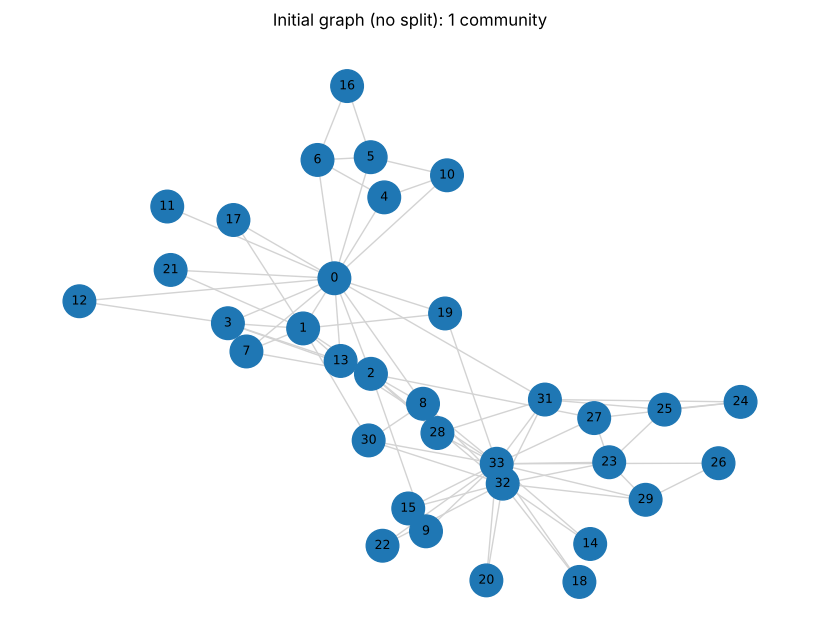

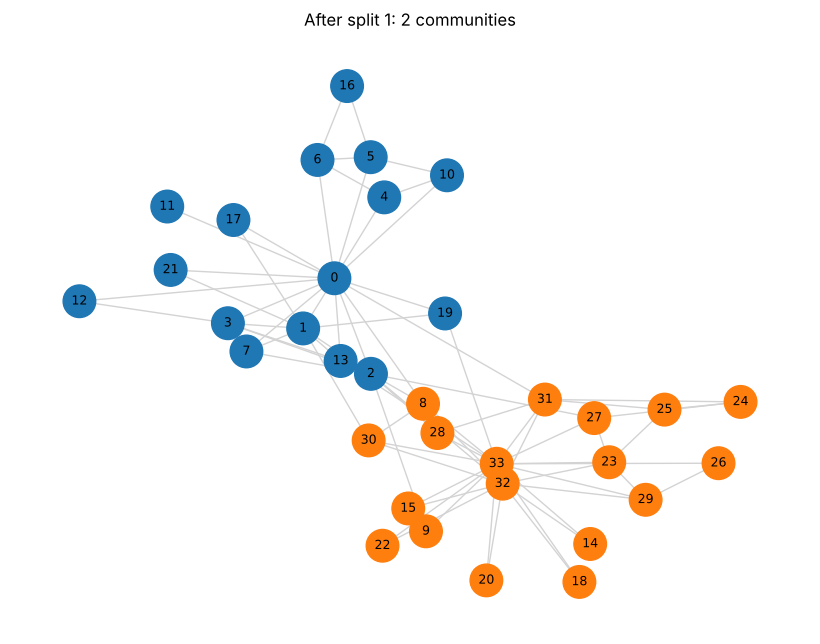

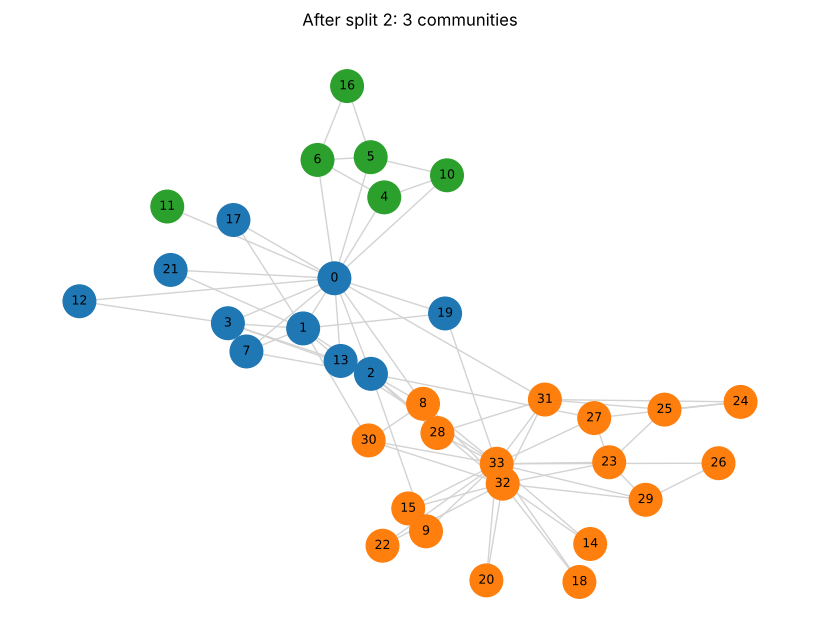

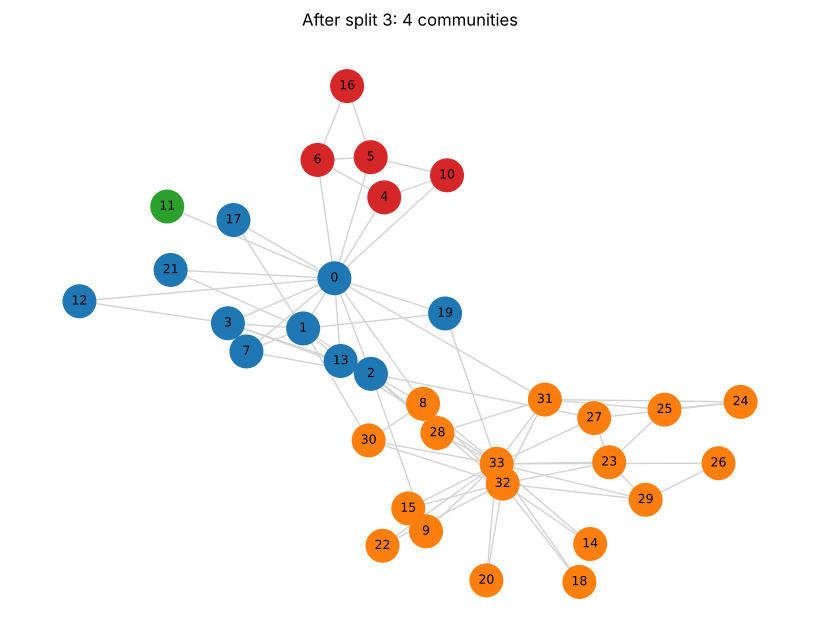

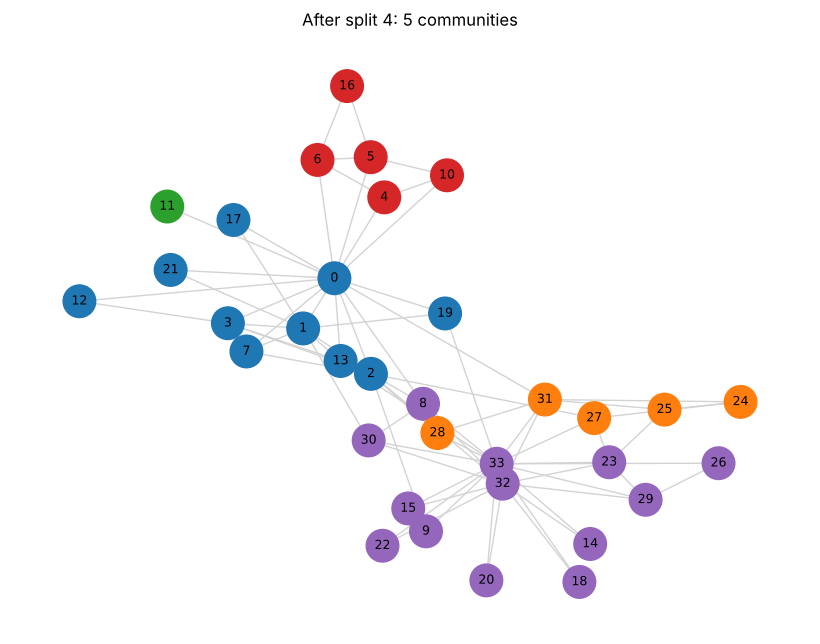

In [5]:
pos = nx.spring_layout(G, seed=42)
cmap = plt.get_cmap("tab10")

def plot_partition(partition, title):
    colour_of = {v: cmap(cid % 10) for cid, members in partition.items() for v in members}
    plt.figure(figsize=(8, 6))
    nx.draw(G, pos, with_labels=True, node_color=[colour_of[v] for v in G.nodes()],
            node_size=550, font_size=9, edge_color="lightgray")
    plt.title(title)
    plt.show()

for t, partition in enumerate(history):
    label = "Initial graph (no split)" if t == 0 else f"After split {t}"
    plot_partition(partition, f"{label}: {len(partition)} communit{'y' if len(partition) == 1 else 'ies'}")

## 5. Node metrics after each split
After every split (and for the initial graph, iteration 0) the four metrics are computed with NetworkX **inside each community's induced subgraph**, and every node receives the value from its own community. Computing them on the whole graph would give the same numbers at every iteration, because splitting does not change the edges. `metrics[iteration][metric_name][node]` holds the results.

In [6]:
METRICS = {
    "Degree centrality": nx.degree_centrality,
    "Betweenness centrality": nx.betweenness_centrality,
    "Closeness centrality": nx.closeness_centrality,
    "Clustering coefficient": nx.clustering,
}

def compute_metrics(partition):
    """Return {metric name: {node: value}}, each node scored within its own community."""
    result = {name: {} for name in METRICS}
    for members in partition.values():
        sub = G.subgraph(members)
        for name, func in METRICS.items():
            result[name].update(func(sub))
    return result

metrics = {t: compute_metrics(partition) for t, partition in enumerate(history)}

# Iteration 0 = the whole graph: the five highest-scoring nodes per metric
for name in METRICS:
    top = sorted(metrics[0][name].items(), key=lambda kv: -kv[1])[:5]
    print(f"{name:<24}", ", ".join(f"node {v}: {x:.4f}" for v, x in top))

Degree centrality        node 33: 0.5152, node 0: 0.4848, node 32: 0.3636, node 2: 0.3030, node 1: 0.2727
Betweenness centrality   node 0: 0.4376, node 33: 0.3041, node 32: 0.1452, node 2: 0.1437, node 31: 0.1383
Closeness centrality     node 0: 0.5690, node 2: 0.5593, node 33: 0.5500, node 31: 0.5410, node 8: 0.5156
Clustering coefficient   node 7: 1.0000, node 12: 1.0000, node 14: 1.0000, node 15: 1.0000, node 16: 1.0000


## 6. Evolution of the metrics across iterations

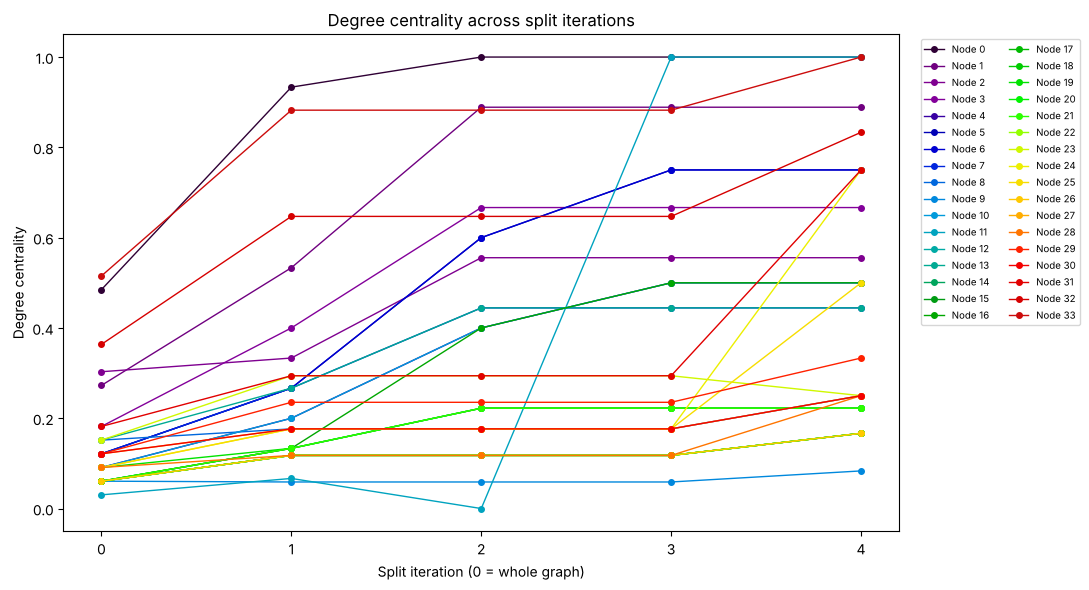

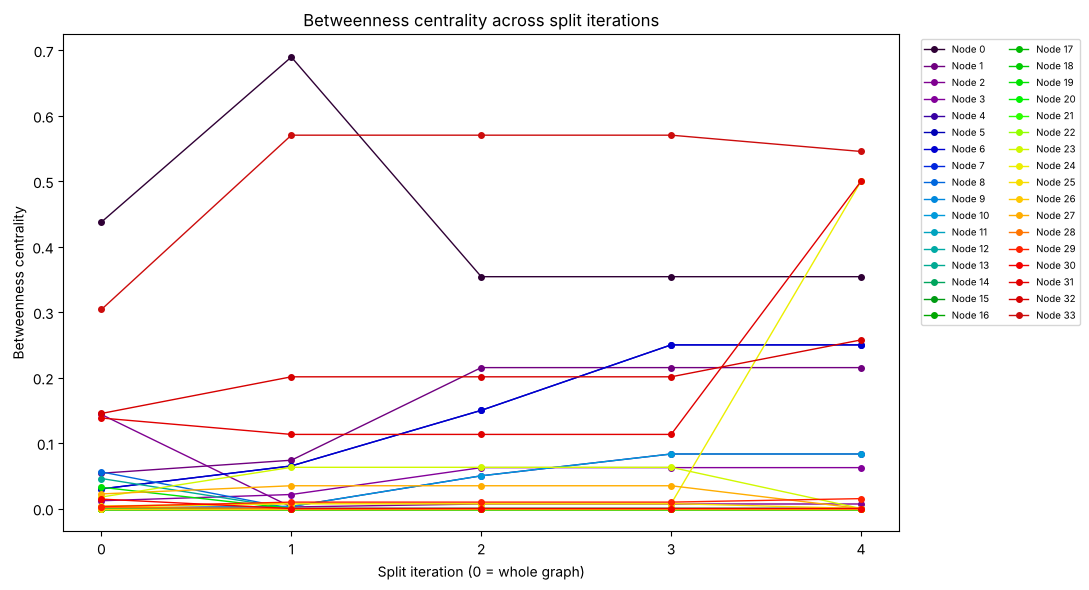

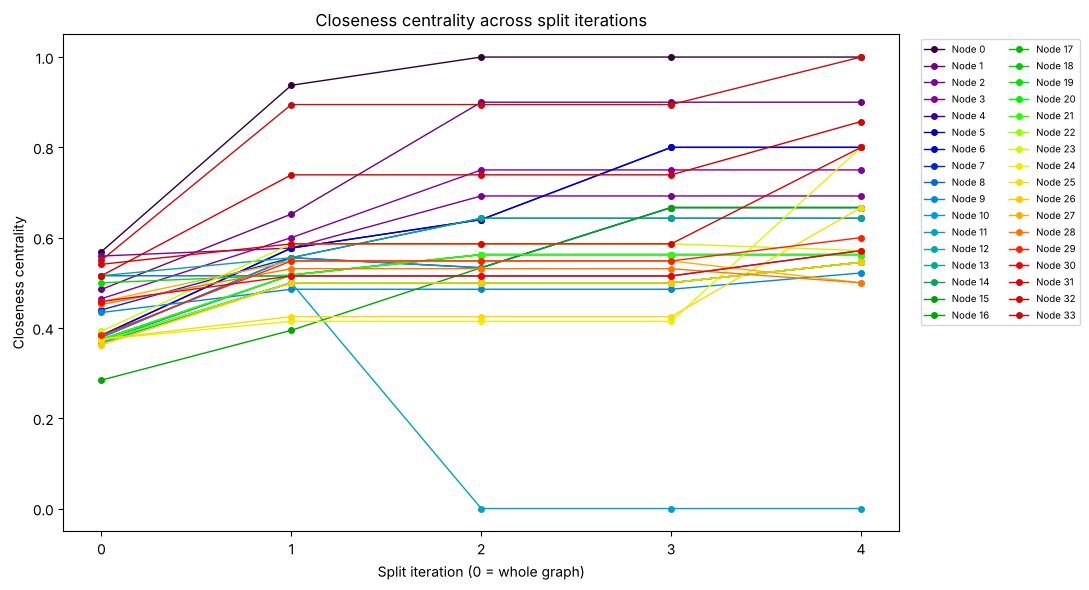

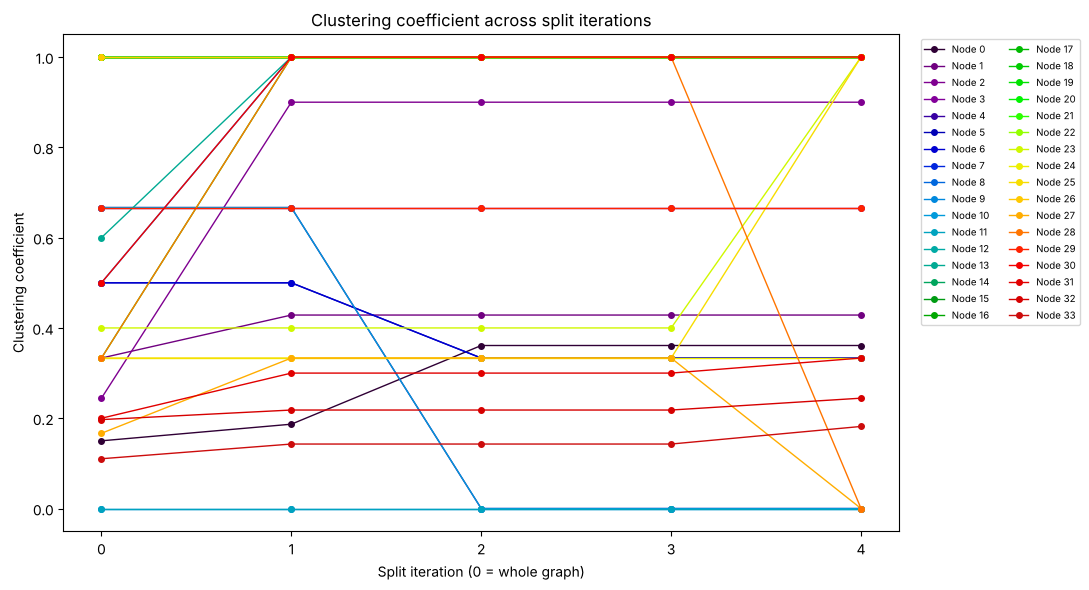

In [7]:
iterations = list(metrics)
line_colours = plt.get_cmap("nipy_spectral")(np.linspace(0.02, 0.95, n))

for name in METRICS:
    plt.figure(figsize=(11, 6))
    for colour, v in zip(line_colours, nodes):
        plt.plot(iterations, [metrics[t][name][v] for t in iterations],
                 marker="o", linewidth=1, markersize=4, color=colour, label=f"Node {v}")
    plt.xticks(iterations)
    plt.xlabel("Split iteration (0 = whole graph)")
    plt.ylabel(name)
    plt.title(f"{name} across split iterations")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left", ncol=2, fontsize=7)
    plt.tight_layout()
    plt.show()

## 7. Verification

In [8]:
def modularity_Q(partition):
    """Q = (1/2m) * sum over pairs in the same community of B_ij."""
    return sum(B[np.ix_(c, c)].sum() for c in partition.values()) / (2 * m)

print("Iteration | communities | Q (own formula) | Q (NetworkX)")
for t, partition in enumerate(history):
    q_own = modularity_Q(partition)
    q_nx = nx.community.modularity(G, [set(c) for c in partition.values()], weight=None)
    assert np.isclose(q_own, q_nx)
    print(f"{t:>9} | {len(partition):>11} | {q_own:>15.4f} | {q_nx:>12.4f}")

# Every node appears in exactly one final community
all_members = [v for c in final_communities.values() for v in c]
assert sorted(all_members) == nodes
print("\nFinal communities:")
for cid, members in final_communities.items():
    print(f"  Community {cid} ({len(members)} nodes): {members}")

# First split versus the real split of the club
side_1 = set(history[1][0])
hi = {v for v in nodes if G.nodes[v]["club"] == "Mr. Hi"}
wrong = sorted(side_1 ^ hi) if len(side_1 ^ hi) <= n / 2 else sorted(set(nodes) - (side_1 ^ hi))
print(f"\nFirst split vs. real club split: {n - len(wrong)}/{n} nodes agree; mismatched node(s): {wrong}")

Iteration | communities | Q (own formula) | Q (NetworkX)
        0 |           1 |         -0.0000 |       0.0000
        1 |           2 |          0.3715 |       0.3715
        2 |           3 |          0.3898 |       0.3898
        3 |           4 |          0.3911 |       0.3911
        4 |           5 |          0.4094 |       0.4094

Final communities:
  Community 0 (10 nodes): [0, 1, 2, 3, 7, 12, 13, 17, 19, 21]
  Community 1 (5 nodes): [24, 25, 27, 28, 31]
  Community 2 (1 nodes): [11]
  Community 3 (5 nodes): [4, 5, 6, 10, 16]
  Community 4 (13 nodes): [8, 9, 14, 15, 18, 20, 22, 23, 26, 29, 30, 32, 33]

First split vs. real club split: 33/34 nodes agree; mismatched node(s): [8]


## 8. Discussion

**Method and result.** The leading eigenvector of $B$ splits the 34 members into groups of 16 and 18 ($Q=0.3715$). This agrees with the real split of the club for 33 of 34 members; only node 8 is on the other side, and its neighbours lie in both factions. Three further splits give five communities with $Q=0.4094$. The 10-node and 5-node communities have $\lambda_1>0$, but their leading eigenvector has a single sign, so the sign rule cannot divide them (see the table in Section 3). This is a limitation of using the plain block $B^{(C)}$, as the handout specifies, instead of Newman's generalised matrix, whose rows sum to zero. Node 11 (degree 1, attached to node 0) ends up as a singleton.

**Which nodes stay central.** Nodes 33 and 0, the two leaders in the real split, dominate the network. At iteration 0, node 33 has the highest degree centrality (0.5152) and node 0 the highest betweenness (0.4376) and closeness (0.5690). Node 0 has the top closeness at every iteration, and node 33 is in the top three for closeness at every iteration. Node 33 is the top node for betweenness from iteration 2 on, whereas node 0's betweenness drops from 0.690 to 0.354 once its group is divided. Node 0 is adjacent to every other member of its 10-node community, so its within-community degree centrality is 1.0. Nodes 1, 2 and 32 are the next most central.

**How community structure shapes the metrics.**
* *Clustering rises inside communities.* Node 8 goes from 0.50 to 1.00 and node 2 from 0.24 to 0.90 after the first split, because their neighbours inside the community are densely linked. Nodes 7 and 12 stay at 1.0 throughout. Hub node 33 stays low (0.11 to 0.18) because its neighbours are mostly not connected to each other: it bridges groups rather than sitting in a clique.
* *Betweenness measures bridging.* Node 8 falls from 0.056 to 0 after the first split, and node 2 from 0.144 to 0.002, because the shortest paths they sat on mostly crossed between groups, and those paths are no longer inside any single subgraph.
* *Degree and closeness rise in small communities.* They are normalised by $|C|-1$, so a node in a small community scores higher even though its connections have not changed. Examples are node 31 (closeness 0.54 to 0.80) and node 1 (degree 0.27 to 0.89). Compare ranks within an iteration, not raw values across iterations.
* *Singleton artefact.* NetworkX gives a one-node subgraph a degree centrality of 1 and a closeness of 0. Node 11 in the plots reflects this convention, not a real change in the graph.

These values describe nodes **within their current community** and not changes to the original graph, whose edges never change.

## References
Newman, M. E. J. (2006). Modularity and community structure in networks. *Proceedings of the National Academy of Sciences*, 103(23), 8577–8582. https://doi.org/10.1073/pnas.0601602103

Zachary, W. W. (1977). An information flow model for conflict and fission in small groups. *Journal of Anthropological Research*, 33(4), 452–473.